# Globular clusters in a live Milky Way: Pal 5

Pal 5 on its observed orbit (Baumgardt's catalogue + Gaia EDR3 proper motions), integrated back in time
and then forward to the present **in a live N-body Milky Way**, with jaccpot's `ProductionRunner` and
nornax's hybrid Hermite clusters (`ClustersRunnerScheme`): the cluster's own stars are a direct-sum
Hermite-4 system, the galaxy an FMM, and stars beyond 2 r_J are stripped into the galaxy's rows.

The sanity check is the same cluster as a plain N-body system in Odisseo's **static** Milky Way potential,
fitted to the live model: the stream should agree to within the live-vs-static difference.

Every run is a script in `notebooks/gc_in_mw/` writing to `$ODISSEO_GC_RUNS` (resumable: rerun the same
command); this notebook only launches them and plots. See `docs/source/globular_clusters.md`.

**Modes.** `SMALL = True` (default) runs a CPU version (galaxy 5000, M = 64, 2 Myr; ~10-20 min, compile-dominated): it
tests the pipeline, not the physics. `SMALL = False` is the GPU demo whose figures are committed below
(galaxy 1e6, M = 4096, 1 Gyr: back 1 Gyr, then forward to the present; run the scripts on a GPU, e.g. through `on-free-card`).
`RUN = False` only plots existing outputs.

In [1]:
import os, subprocess, sys, json
from IPython.display import Image, display

SMALL = bool(int(os.environ.get("GC_SMALL", "1")))   # CPU small mode
RUN = bool(int(os.environ.get("GC_RUN", "1")))       # launch the scripts (else: plot existing outputs)
HERE = os.path.abspath("gc_in_mw") if os.path.isdir("gc_in_mw") else os.path.abspath(".")
REPO = os.path.abspath(os.path.join(HERE, "..", ".."))
RUNS = os.environ.setdefault("ODISSEO_GC_RUNS", os.path.join(HERE, "runs"))
DATA = os.environ.setdefault("ODISSEO_GC_DATA", os.path.join(RUNS, "catalogue"))
JAX_PY = os.environ.get("GC_JAX_PYTHON", sys.executable)      # jax >= 0.11.2 + jaccpot + nornax
AGAMA_PY = os.environ.get("GC_AGAMA_PYTHON", sys.executable)  # agama (ICs, prepare)
PREFIX = os.environ.get("GC_GPU_PREFIX", "").split()          # e.g. "on-free-card 20" for the GPU runs
N_GAL = 100_000 if SMALL else 1_000_000
GALAXY = os.path.join(RUNS, "ics", f"mw_{N_GAL}.npz")
TAG = "small" if SMALL else "1gyr"
PREP, LIVE, STATIC, FIGS = (os.path.join(RUNS, f"{x}_{TAG}") for x in ("prepare", "pal5_live", "pal5_static", "figs"))
T_GYR = 0.002 if SMALL else 1.0

def run(args, py=JAX_PY, prefix=()):
    cmd = [*prefix, py, *args]
    print("$", " ".join(cmd), flush=True)
    if RUN:
        out = subprocess.run(cmd, cwd=REPO, capture_output=True, text=True)
        print(out.stdout[-3000:])
        if out.returncode:
            print(out.stderr[-3000:])
            raise RuntimeError(f"rc={out.returncode}")
print(TAG, RUNS)

1gyr /export/scratch/tbuck/mn-scratch/hh4b/runs


## 1. The catalogue

`tools/fetch_baumgardt.py` downloads the orbit and structure tables and records URL, date and sha256
(`SOURCE.json`). `odisseo.globular_clusters` parses them; Galactocentric coordinates come from astropy's
`Galactocentric` frame (its defaults; `BAUMGARDT_FRAME` reproduces the catalogue's own columns).

In [2]:
if not os.path.exists(os.path.join(DATA, "SOURCE.json")):
    run(["tools/fetch_baumgardt.py", "--out", DATA])
sys.path.insert(0, REPO)
from odisseo import globular_clusters as gc
cat = gc.load_baumgardt(directory=DATA)
for row in gc.cluster_table(["Pal 5", "NGC 5466", "M68"], cat):
    print(f"{row['name']:9s} x = {row['x'] * 10} kpc, M = {row['mass_msun']:.3g} Msun, "
          f"r_h = {row['r_half_pc']} pc, W0 = {row['w0']:.2f}")

Pal_5     x = [ 7.19709249  0.22368771 15.7255695 ] kpc, M = 1.34e+04 Msun, r_h = 27.63 pc, W0 = 2.03
NGC_5466  x = [-4.70653962  3.05568039 15.47563839] kpc, M = 5.61e+04 Msun, r_h = 13.75 pc, W0 = 5.32
NGC_4590  x = [-3.94980334 -7.30916175  6.13055873] kpc, M = 1.28e+05 Msun, r_h = 7.27 pc, W0 = 7.32


## 2. The live Milky Way

The a4 `galaxy` model of `tools/a4_galaxy_ics.py` (agama self-consistent: exponential disc 6e10 Msun,
R_d 2.4 kpc; Hernquist bulge 1.2e10 Msun, a = 0.8 kpc; NFW halo 1e12 Msun, r_s 20 kpc, cut off at
100 kpc), seed 7, with its potential exported for step 3.

In [3]:
os.makedirs(os.path.dirname(GALAXY), exist_ok=True)
if not os.path.exists(GALAXY):
    run(["tools/a4_galaxy_ics.py", "galaxy", "--output", GALAXY, "--n-particles", str(N_GAL), "--seed", "7",
         "--export-potential", GALAXY.replace(".npz", ".pot.ini")], py=AGAMA_PY)

$ /export/home/tbuck/micromamba/envs/odisseo/bin/python tools/a4_galaxy_ics.py galaxy --output /export/scratch/tbuck/mn-scratch/hh4b/runs/ics/mw_1000000.npz --n-particles 1000000 --seed 7 --export-potential /export/scratch/tbuck/mn-scratch/hh4b/runs/ics/mw_1000000.pot.ini


## 3. The static potential and the orbit back in time

`prepare.py` fits Odisseo's static MW (NFW + MN3 disc + Hernquist bulge) to the live model's potential where
the orbit goes, and integrates Pal 5's present position back by `T_GYR` in the live model's potential.

In [4]:
run(["notebooks/gc_in_mw/prepare.py", "--potential", GALAXY.replace(".npz", ".pot.ini"), "--names", "Pal 5",
     "--t-gyr", str(T_GYR), "--out", PREP], py=AGAMA_PY)
prep = json.load(open(os.path.join(PREP, "prepare.json")))
print(json.dumps({k: prep[k] for k in ("fit_params", "fit_stats", "vc_kms_at_8kpc",
                                        "present_offset_static_vs_live_kpc")}, indent=1))

$ /export/home/tbuck/micromamba/envs/odisseo/bin/python notebooks/gc_in_mw/prepare.py --potential /export/scratch/tbuck/mn-scratch/hh4b/runs/ics/mw_1000000.pot.ini --names Pal 5 --t-gyr 1.0 --out /export/scratch/tbuck/mn-scratch/hh4b/runs/prepare_1gyr


{
 "fit_params": {
  "halo_M": 113.54514106400266,
  "halo_rs": 2.2891845826447494,
  "disc_M": 6.817617758667329,
  "disc_hr": 0.3851357107188257,
  "disc_hz": 0.09999999999931289,
  "bulge_M": 1.2,
  "bulge_a": 0.08
 },
 "fit_stats": {
  "nominal": {
   "orbit": {
    "median": 0.05156657401872532,
    "p90": 0.10113075726274513,
    "max": 0.22468299176370685
   },
   "3-30kpc": {
    "median": 0.06933864589938113,
    "p90": 0.41294851071930283,
    "max": 1.2409756756084076
   }
  },
  "fit": {
   "orbit": {
    "median": 0.015496775194240437,
    "p90": 0.05159644160589726,
    "max": 0.1059155664752613
   },
   "3-30kpc": {
    "median": 0.03743924720227153,
    "p90": 0.12633546054349115,
    "max": 0.32705680612237803
   }
  }
 },
 "vc_kms_at_8kpc": {
  "live": 249.63353482099825,
  "static": 238.945402373765
 },
 "present_offset_static_vs_live_kpc": [
  2.7397544785857155
 ]
}


## 4. The runs

Live: `run_live.py` (ProductionRunner + ClustersRunnerScheme, one card). Static: `run_static.py`
(Odisseo's direct-sum leapfrog in the fitted static potential). Same stars (King model, W0 from the
catalogue's concentration, seed 0).

In [5]:
small = ["--small"] if SMALL else []
gpu = [] if SMALL else ["--steps", "100", "--energy-every", "3", "--snap-every", "5", "--restart-every", "2"]
run(["notebooks/gc_in_mw/run_live.py", "--galaxy", GALAXY, "--prepare", PREP, "--M", "4096", "--out", LIVE,
     *small, *gpu], prefix=PREFIX)
run(["notebooks/gc_in_mw/run_static.py", "--prepare", PREP, "--M", "4096", "--out", STATIC,
     *small])

$ /export/home/tbuck/micromamba/envs/odisseo/bin/python notebooks/gc_in_mw/run_live.py --galaxy /export/scratch/tbuck/mn-scratch/hh4b/runs/ics/mw_1000000.npz --prepare /export/scratch/tbuck/mn-scratch/hh4b/runs/prepare_1gyr --M 4096 --out /export/scratch/tbuck/mn-scratch/hh4b/runs/pal5_live_1gyr --steps 100 --energy-every 3 --snap-every 5 --restart-every 2


$ /export/home/tbuck/micromamba/envs/odisseo/bin/python notebooks/gc_in_mw/run_static.py --prepare /export/scratch/tbuck/mn-scratch/hh4b/runs/prepare_1gyr --M 4096 --out /export/scratch/tbuck/mn-scratch/hh4b/runs/pal5_static_1gyr


## 5. Conservation, stripping and the stream

$ /export/home/tbuck/micromamba/envs/odisseo/bin/python notebooks/gc_in_mw/analyse.py --prepare /export/scratch/tbuck/mn-scratch/hh4b/runs/prepare_1gyr --live /export/scratch/tbuck/mn-scratch/hh4b/runs/pal5_live_1gyr --static /export/scratch/tbuck/mn-scratch/hh4b/runs/pal5_static_1gyr --out /export/scratch/tbuck/mn-scratch/hh4b/runs/figs_1gyr


{
 "live": {
  "time_myr": 74.55,
  "n_members": 4084,
  "n_stripped": 12,
  "progenitor_kpc": [
   -9.688448798830501,
   -9.966204470251064,
   -0.4978608217494972
  ],
  "energy_ledgered_drift_max": 7.886761085068771e-08,
  "momentum_drift_max": 8.865365247629927e-09,
  "replans": 4,
  "retries": 4,
  "device_peak_gb": 1.038285902
 },
 "progenitor_offset_live_vs_static_kpc": 0.14130053338220466,
 "point_orbit_offset_live_model_vs_static_kpc": 0.16187204001489613,
 "track": {
  "bins_deg": [
   -0.1974782805609692,
   0.1991709957922756,
   30
  ],
  "bins_compared": 28,
  "dphi2_median_deg": 0.006253998949359279,
  "dphi2_max_deg": 0.023499443462304207,
  "dr_rel_median": 0.0001499986770859274,
  "stream_width_phi2_deg": NaN,
  "extent_live_deg": [
   -0.16315411469931465,
   0.16000615086678985
  ],
  "extent_static_deg": [
   -0.18483293424499667,
   0.1915519389870427
  ]
 }
}


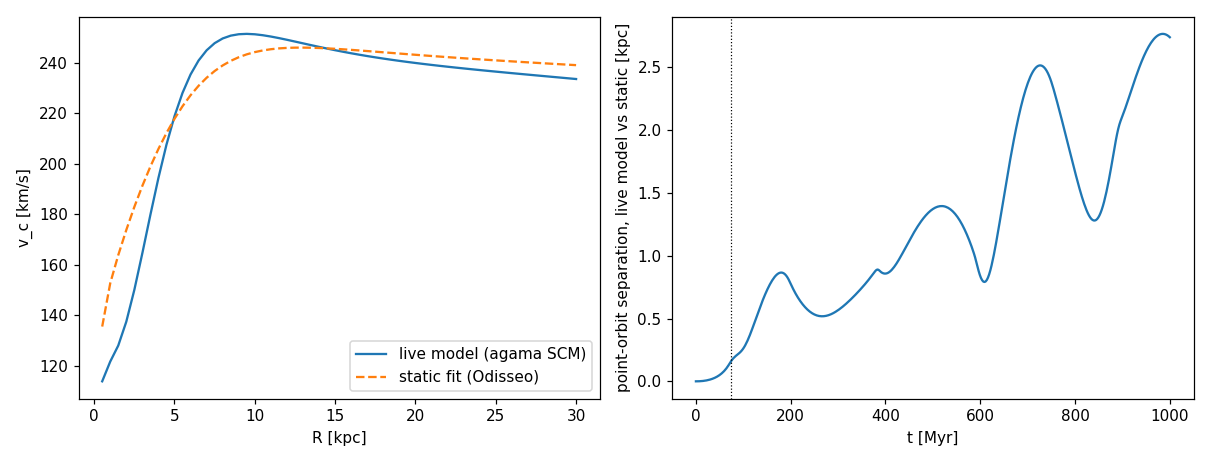

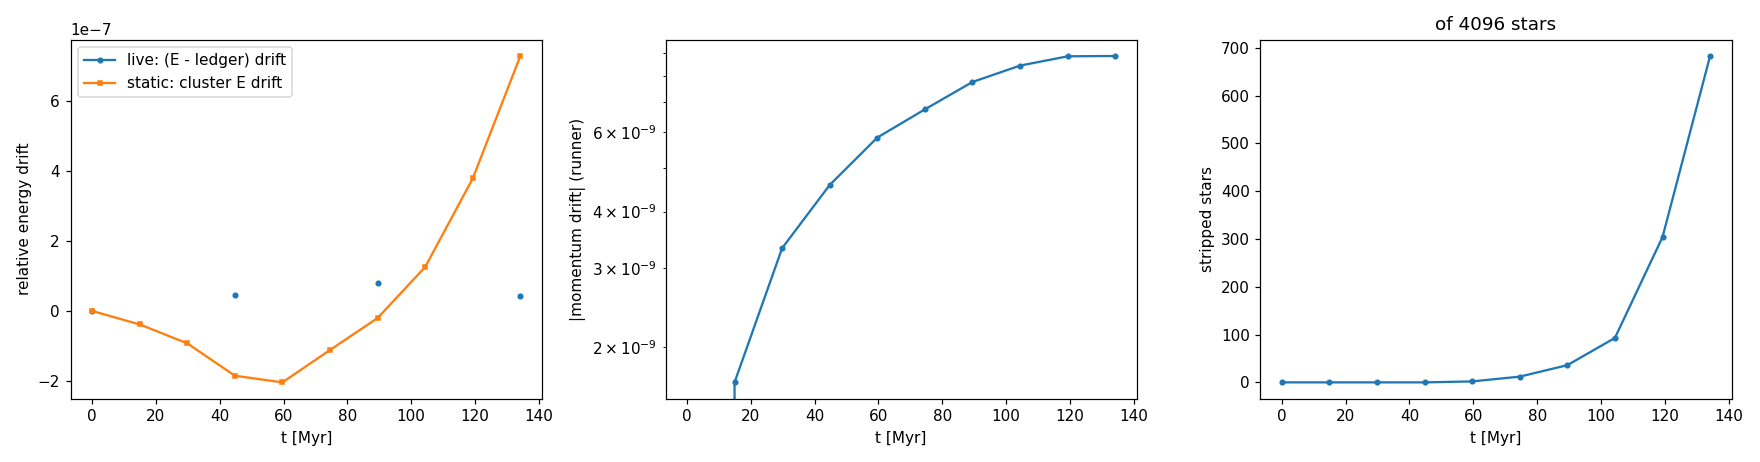

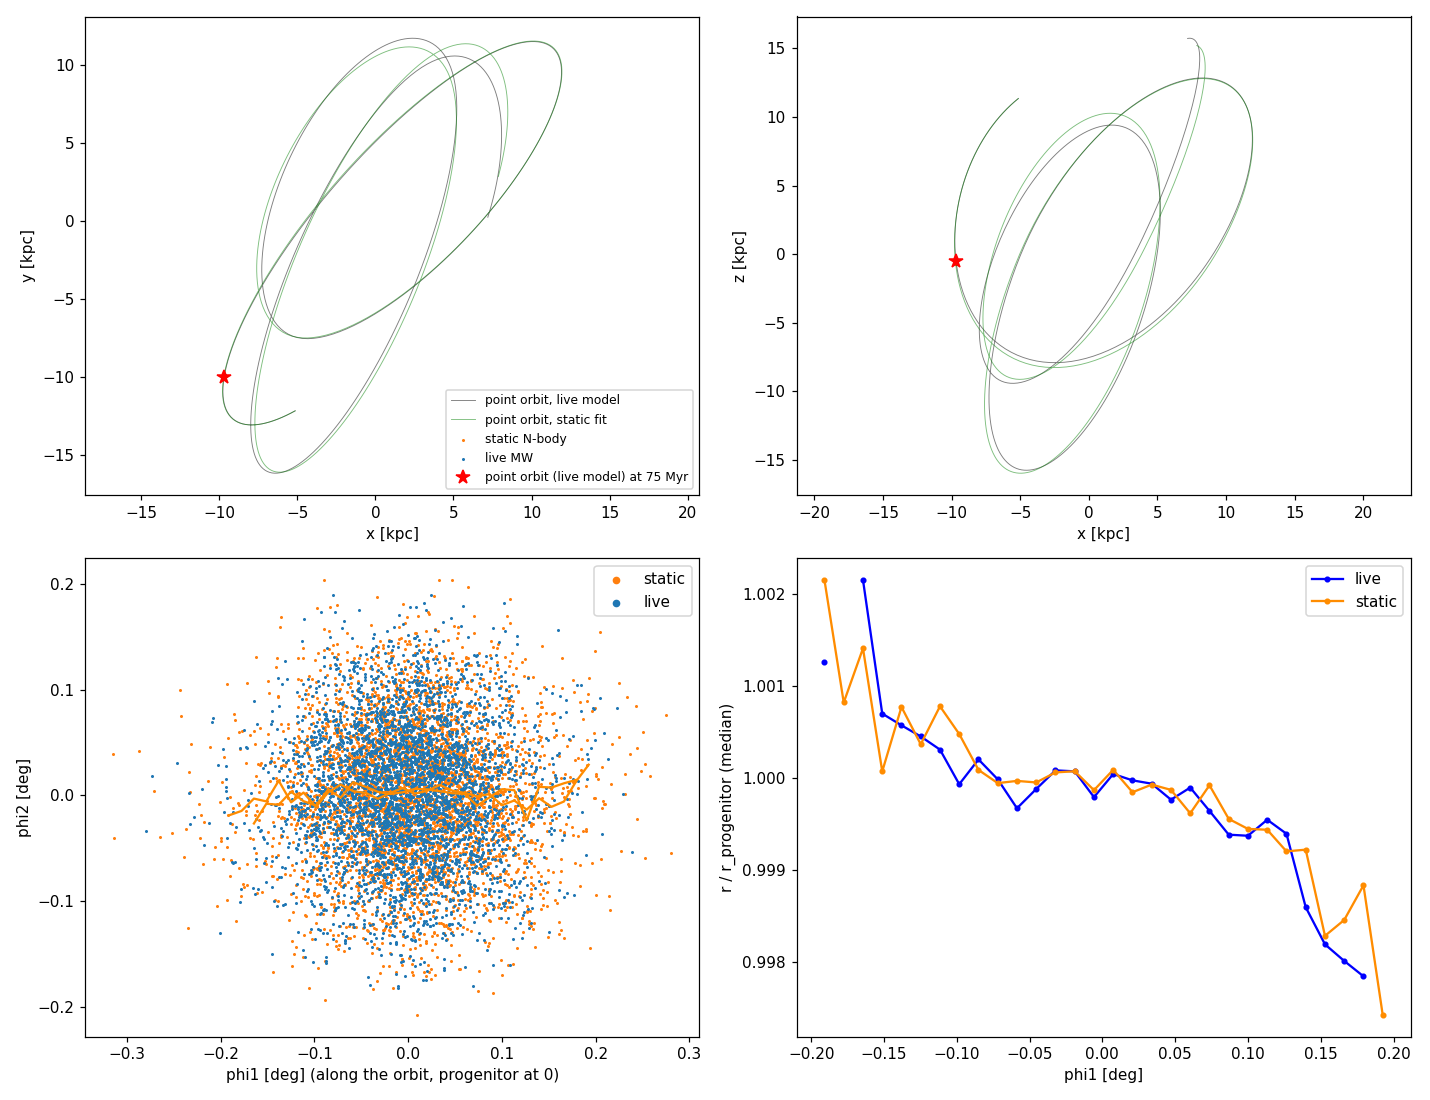

In [6]:
run(["notebooks/gc_in_mw/analyse.py", "--prepare", PREP, "--live", LIVE, "--static", STATIC, "--out", FIGS],
    py=AGAMA_PY)
summary = json.load(open(os.path.join(FIGS, "summary.json")))
print(json.dumps({k: summary[k] for k in ("live", "progenitor_offset_live_vs_static_kpc",
                                           "point_orbit_offset_live_model_vs_static_kpc", "track")}, indent=1))
for f in ("potential.png", "conservation.png", "stream.png"):
    display(Image(os.path.join(FIGS, f), width=900))

## 6. The K ~ 150 bundle

Every catalogue cluster with a mass and a half-mass radius (K = 165, M = 1000 stars each) at today's
positions in the live MW: `run_live.py --names ALL`. The functional run (a few segments) and the long run
are in `notebooks/gc_in_mw/bundle.sh`; scaling numbers are HoreKa's. The figure is the functional run
(1e7 galaxy, 4 segments x 10 steps).

$ /export/home/tbuck/micromamba/envs/odisseo/bin/python notebooks/gc_in_mw/analyse_bundle.py --run /export/scratch/tbuck/mn-scratch/hh4b/runs/bundle_functional --out /export/scratch/tbuck/mn-scratch/hh4b/runs/figs_1gyr


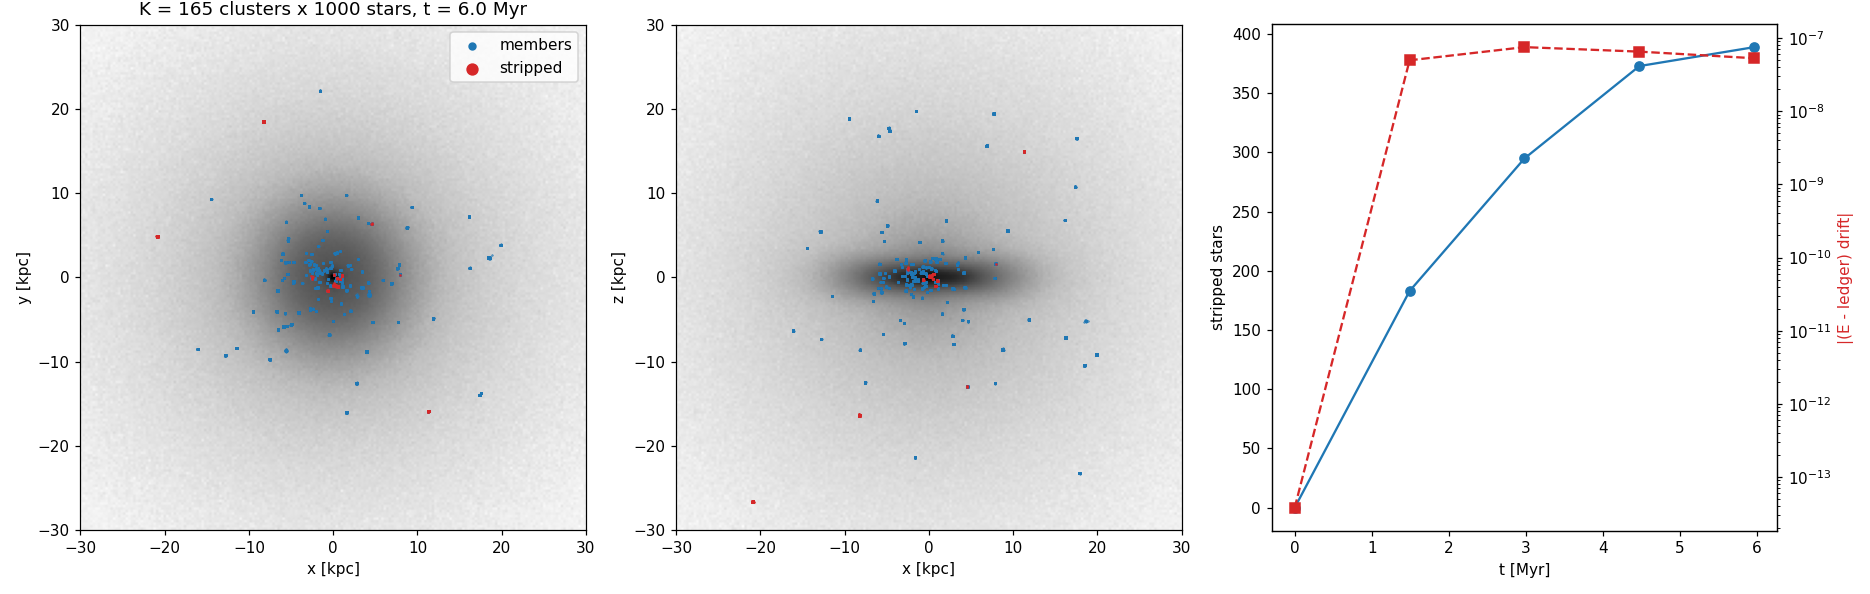

In [7]:
BUNDLE = os.path.join(RUNS, "bundle_functional")
if os.path.exists(os.path.join(BUNDLE, "done.json")):
    run(["notebooks/gc_in_mw/analyse_bundle.py", "--run", BUNDLE, "--out", FIGS], py=AGAMA_PY)
    display(Image(os.path.join(FIGS, "bundle.png"), width=900))
else:
    print("no bundle run under", BUNDLE, "(notebooks/gc_in_mw/bundle.sh functional)")